In [2]:
import math
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.metrics import r2_score


import torch
import torch.nn as nn 
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
from torch.optim import lr_scheduler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [3]:
df = pd.read_csv('../ML-Aided-NR-V2X-QoS-Predictions/dataset.csv')
df = df.drop(columns=['Unnamed: 0']) 
df.head()

,X,Y,throughput,mcs,distance,pktsize,delay,jitter,sinr,power,dlpathloss,pdr
0,146.601387,368.116530,1.743593,13,184.225706,190,3.242855,0.000000,-1.38581,15,-95.2246,99
1,143.260663,365.862937,1.743592,13,188.238131,190,6.579737,1.241554,-3.11075,15,-95.3060,99
2,137.782258,362.167301,1.743593,13,194.819602,190,3.242855,0.000000,-1.24068,15,-95.5003,99
3,131.346059,357.825556,1.743592,13,202.553954,190,6.579767,1.241449,-3.51258,15,-95.8110,99
4,128.942275,355.120683,1.742541,13,206.124022,190,9.782037,1.008803,-3.02864,15,-96.1639,99


In [4]:
df.drop_duplicates(inplace=True)
df.shape

(8720, 12)

In [5]:
print(df.isnull().sum())

X                0
Y                0
throughput       0
mcs              0
distance       103
pktsize          0
delay            0
jitter        3097
sinr             0
power            0
dlpathloss       0
pdr              0
dtype: int64


Missing range of jitter

In [6]:
import pandas as pd

# Find where jitter is NaN
missing_mask = df['jitter'].isna()

# Assign group numbers to consecutive runs of True/False
missing_groups = (missing_mask != missing_mask.shift()).cumsum()

# Only keep the NaN groups, then find start and end index of each
nan_ranges = df[missing_mask].groupby(missing_groups).apply(
    lambda g: pd.Series({'Start_Index': g.index[0], 'End_Index': g.index[-1]})
).reset_index(drop=True)

print(nan_ranges)

   Start_Index  End_Index
0         2892       6029


In [7]:
cols = ['throughput', 'pktsize', 'delay', 'pdr', 'jitter']
num_col = len(cols)
data = df[cols].copy()
print(cols)
data.dropna(inplace=True)

['throughput', 'pktsize', 'delay', 'pdr', 'jitter']


# Correlation Map

In [8]:
# numeric_df = data.select_dtypes(include='number')
# numeric_df = numeric_df.dropna(subset=['jitter'])

# jitter_corr = numeric_df.corr()['jitter'].drop('jitter')  

# # Plot
# plt.figure(figsize=(8,4))
# sns.barplot(x=jitter_corr.values, y=jitter_corr.index)
# plt.title("Correlation of jitter")
# plt.xlabel("Correlation Coefficient")
# plt.axvline(0, color='gray', linestyle='--')
# plt.tight_layout()
# plt.show()

# Data Imputation

In [9]:
from sklearn.linear_model import LinearRegression

clean = data[['jitter', 'delay']].dropna()

model = LinearRegression()
model.fit(clean[['delay']], clean[['jitter']])

missing_jitter = df['jitter'].isnull()
# print(missing_jitter)
predicted = model.predict(df.loc[missing_jitter, ['delay']])
df.loc[missing_jitter, 'jitter'] = predicted

In [10]:
from sklearn.linear_model import LinearRegression

clean = df[['distance', 'pdr']].dropna()

model = LinearRegression()
model.fit(clean[['pdr']], clean[['distance']])

missing_dist= df['distance'].isnull()
# print(missing_jitter)
predicted = model.predict(df.loc[missing_dist, ['pdr']])
df.loc[missing_dist, 'distance'] = predicted

In [11]:
df.isnull().sum()

X             0
Y             0
throughput    0
mcs           0
distance      0
pktsize       0
delay         0
jitter        0
sinr          0
power         0
dlpathloss    0
pdr           0
dtype: int64

# EDA

In [12]:
# import seaborn as sns

# plt.figure(figsize=(12, 6))
# sns.lineplot(x=df.index, y='jitter', data=df, label='Jitter')
# plt.xlabel("Row Number")
# plt.ylabel("Value")
# plt.title("Jitter")
# plt.legend()
# plt.grid(True)
# plt.show()

## AutoCorrelation

In [13]:
# from pandas.plotting import autocorrelation_plot

# plt.figure(figsize=(10, 4))
# autocorrelation_plot(df['jitter'])
# plt.title("Autocorrelation of Jitter")
# plt.show()


## Segment Wise Analysis

In [14]:
# import numpy as np

# segment_size = 1000
# num_segments = len(df) // segment_size

# segment_stats = []

# for i in range(num_segments):
#     seg = df.iloc[i * segment_size: (i + 1) * segment_size]
#     stats = {
#         'segment': i,
#         'jitter_mean': seg['jitter'].mean(),
#         'jitter_std': seg['jitter'].std(),
#     }
#     segment_stats.append(stats)

# seg_df = pd.DataFrame(segment_stats)

# plt.figure(figsize=(8,4))
# plt.plot(seg_df['segment'], seg_df['jitter_mean'], label='Jitter Mean')
# plt.xlabel("Segment Number")
# plt.ylabel("Mean Value")
# plt.title("Segment-wise Mean of Jitter")
# plt.legend()
# plt.grid(True)
# plt.show()

# Data Augmentation

In [15]:
def sliding_window_augmentation(df, cols, L=100, s=10, add_noise=True, noise_level=0.02):
    X = df[cols].values
    T, D = X.shape
    n_windows = max(0,(T - L) // s + 1)
    windows = np.zeros((n_windows, L, D))

    col_stds = df[cols].std().values

    for i in range(n_windows):
        start = i * s
        end = start + L
        w = X[start:end].copy()

        if add_noise:
            noise = np.random.randn(*w.shape) * (col_stds * noise_level)
            w += noise

        windows[i] = w

    return windows

windows = sliding_window_augmentation(data, cols, L=100, s=10, add_noise=False)

windows_noisy = sliding_window_augmentation(data, cols, L=100, s=10, add_noise=True, noise_level=0.02)

all_windows = np.concatenate([windows, windows_noisy], axis=0)
print(f"Original rows: {len(data)}")
print(f"Sliding windows     : {windows.shape[0]}")
print(f"Noisy windows       : {windows_noisy.shape[0]}")
print(f"Total augmented     : {all_windows.shape[0]}")

Original rows: 5623
Sliding windows     : 553
Noisy windows       : 553
Total augmented     : 1106


In [16]:
print(f"Total shape: ({len(windows)}, {windows[0].shape[0]}, {windows[0].shape[1]})")

Total shape: (553, 100, 5)


In [17]:
import matplotlib.pyplot as plt

def plot_augmented_windows(windows, windows_noisy, cols, feature_index=0, num_samples=5):
    """
    Plot clean and noisy sliding windows for a specific feature.

    Parameters:
    - windows: ndarray of shape (N, L, D)
    - windows_noisy: same shape
    - cols: list of feature names
    - feature_index: which feature to visualize
    - num_samples: number of sample windows to plot
    """
    plt.figure(figsize=(12, num_samples * 2.5))
    feature_name = cols[feature_index]

    for i in range(num_samples):
        plt.subplot(num_samples, 1, i + 1)
        plt.plot(windows[i, :, feature_index], label='Clean', color='blue')
        plt.plot(windows_noisy[i, :, feature_index], label='Noisy', color='orange', alpha=0.7)
        plt.title(f'Sample {i+1} - Feature: {feature_name}')
        plt.xlabel('Time step')
        plt.ylabel('Value')
        plt.legend(loc='upper right')
        plt.grid(True)

    plt.tight_layout()
    plt.show()

In [18]:
print(cols)

['throughput', 'pktsize', 'delay', 'pdr', 'jitter']


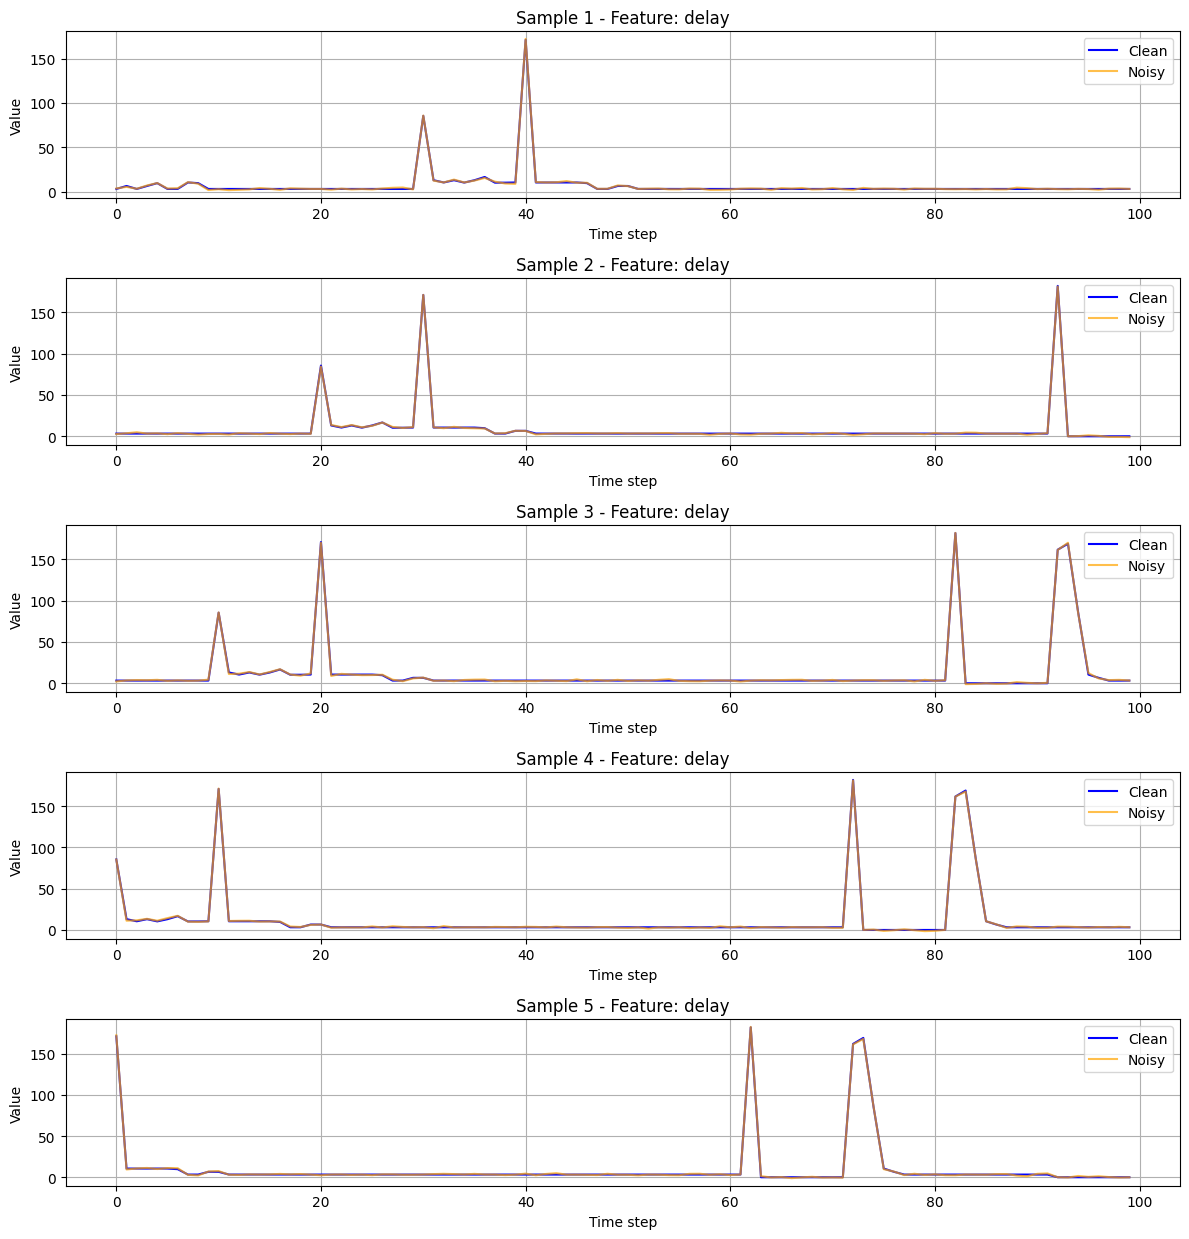

In [19]:
plot_augmented_windows(windows, windows_noisy, cols=cols, feature_index=2, num_samples=5)

# Dataloaders

In [20]:
input_size = len(cols) - 1
print(input_size)

4


In [21]:
class QoSDataset(Dataset):
    def __init__(self, windowed_data, jitter_index):
        self.X = torch.tensor(windowed_data[:, :, [i for i in range(windowed_data.shape[2]) if i != jitter_index]], dtype=torch.float32)
        self.y = torch.tensor(windowed_data[:, :, jitter_index], dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [23]:
dataset = QoSDataset(all_windows, jitter_index=4)

In [24]:
total_len = len(dataset)
train_len = int(0.8 * total_len)
test_len = total_len - train_len

In [25]:
train_dataset, test_dataset = random_split(dataset, [train_len, test_len])

In [26]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# LSTM

In [27]:
class LSTM(nn.Module):
    def __init__(self, input_size=11, output_size=100, hidden_size=50, num_layers=3, dropout=0.3, bidirectional=False):
        super(LSTM, self).__init__()
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional

        self.lstm = nn.LSTM(
            input_size, 
            hidden_size, 
            num_layers, 
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional
        )

        direction_factor = 2 if bidirectional else 1
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * direction_factor, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, output_size)
        )

    def forward(self, x):
        h0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers * (2 if self.bidirectional else 1), x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        out = out[:, -1, :]  # take the last time step
        out = self.fc(out)
        return out

# Scripts

In [28]:
def train(model, trainloader, criterion, optimizer, epoch, scheduler=None):
    model.train()
    epoch_loss = 0

    for X, y in trainloader:
        model.to(DEVICE)
        X, y = X.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        pred = model(X)
        if pred.dim() > y.dim():
            pred = pred.squeeze(-1)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if scheduler is not None:
        scheduler.step()
    
    avg_loss = epoch_loss / len(trainloader)

    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch+1}: Train Loss = {avg_loss:.4f}")
    
    return avg_loss

In [29]:
from sklearn.metrics import r2_score

def validate(model, valloader, criterion, epoch):
    model.eval()
    epoch_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X, y in valloader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            pred = model(X)
            # Ensure dimensions match
            if pred.dim() > y.dim():
                pred = pred.squeeze(-1)
            loss = criterion(pred, y)
            epoch_loss += loss.item()

            all_preds.extend(pred.squeeze().cpu().numpy())
            all_targets.extend(y.cpu().numpy())

    avg_loss = epoch_loss / len(valloader)
    r2 = r2_score(all_targets, all_preds) 

    if (epoch + 1) % 1000 == 0:
        print(f"Epoch {epoch+1}: Val Loss = {avg_loss:.4f}, R² Score = {r2:.4f}")

    return avg_loss, r2

In [31]:
param_grid = {
    # 'learning_rates': [0.00001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1],
    'learning_rates': [0.00001, 0.0005, 0.001, 0.005, 0.01],
    # 'hidden_sizes': [64, 128, 256],
    'hidden_sizes': [64, 128, 256],
    'num_layers': [2, 4],
    'epochs': [5000]
}

In [32]:
for X, y in train_loader:
    print(X.shape)
    print(y.shape)
    break

torch.Size([32, 100, 4])
torch.Size([32, 100])


In [33]:
results = []

for lr in param_grid['learning_rates']:
    for hs in param_grid['hidden_sizes']:
        for nl in param_grid['num_layers']:
            for ep in param_grid['epochs']:
                print(f"lr: {lr} | hs: {hs} | nl: {nl}")
                model = LSTM(input_size=4, output_size=100, hidden_size=hs, num_layers=nl)
                criterion = nn.MSELoss()
                optimizer = optim.Adam(model.parameters(), lr=lr)
                train_losses = []
                val_losses = []
                best_r2 = float('-inf')
                for epoch in range(ep):
                    train_loss = train(model, train_loader, criterion, optimizer, epoch)
                    val_loss, r2 = validate(model, test_loader, criterion, epoch)
                    train_losses.append(train_loss)
                    val_losses.append(val_loss)
                    if r2 > best_r2:
                        best_r2 = r2
                results.append({
                    'lr': lr,
                    'hidden_size': hs,
                    'num_layers': nl,
                    'epochs': ep,
                    'train_losses': train_losses,
                    'val_losses': val_losses,
                    'best_r2': best_r2
                })

lr: 1e-05 | hs: 64 | nl: 2
Epoch 1000: Train Loss = 4.4474
Epoch 1000: Val Loss = 4.6372, R² Score = 0.0796
Epoch 2000: Train Loss = 4.1017
Epoch 2000: Val Loss = 4.4366, R² Score = 0.0950
Epoch 3000: Train Loss = 3.9250
Epoch 3000: Val Loss = 4.2868, R² Score = 0.0688
Epoch 4000: Train Loss = 3.5100
Epoch 4000: Val Loss = 4.0781, R² Score = 0.0713
Epoch 5000: Train Loss = 3.2488
Epoch 5000: Val Loss = 3.9389, R² Score = 0.0946
lr: 1e-05 | hs: 64 | nl: 4
Epoch 1000: Train Loss = 4.3036
Epoch 1000: Val Loss = 4.5171, R² Score = 0.0636
Epoch 2000: Train Loss = 3.7448
Epoch 2000: Val Loss = 4.2216, R² Score = 0.0546
Epoch 3000: Train Loss = 3.4848
Epoch 3000: Val Loss = 4.0763, R² Score = 0.0806
Epoch 4000: Train Loss = 3.2147
Epoch 4000: Val Loss = 4.0252, R² Score = 0.1020
Epoch 5000: Train Loss = 2.9866
Epoch 5000: Val Loss = 3.9355, R² Score = 0.0960
lr: 1e-05 | hs: 128 | nl: 2
Epoch 1000: Train Loss = 3.8399
Epoch 1000: Val Loss = 4.2059, R² Score = 0.0836
Epoch 2000: Train Loss = 3.

In [134]:
import os
import matplotlib.pyplot as plt

os.makedirs("../plots/jitter", exist_ok=True)

for i, result in enumerate(results):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(result['train_losses'], label='Train Loss')
    ax.plot(result['val_losses'], label='Val Loss')
    ax.set_title(f"LR={result['lr']}, Hidden={result['hidden_size']}, Layers={result['num_layers']}, R2={result['best_r2']:.4f}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

    # Save the figure
    filename = f"../plots/jitter/lr{result['lr']}_hs{result['hidden_size']}_nl{result['num_layers']}_r2{result['best_r2']:.4f}.png"
    plt.tight_layout()
    plt.savefig(filename)
    plt.close(fig)

In [135]:
# print(result)

In [136]:
import json

os.makedirs("../results/jitter", exist_ok=True)

def serialize_results(results):
    def make_serializable(d):
        return {
            k: (v.tolist() if hasattr(v, 'tolist') else v)
            for k, v in d.items()
            if k not in ['train_losses', 'val_losses']
        }
    return [make_serializable(r) for r in results]

with open("../results/jitter/results.json", "w") as f:
    json.dump(serialize_results(results), f, indent=4)